In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras



from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Load CIFAR-10 dataset
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

# print("Training images:", x_train_full.shape)
# print("Training labels:", y_train_full.shape)

# print("Test images:", x_test.shape)
# print("Test labels:", y_test.shape)

X_train, X_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full.reshape(-1)
)



print('training length' , len(X_train))
print('testing length',len(x_test))
print('validation length', len(X_val))


training length 40000
testing length 10000
validation length 10000


Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 93s 293ms/step - accuracy: 0.3319 - loss: 1.8073 - val_accuracy: 0.4783 - val_loss: 1.4471
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 88s 280ms/step - accuracy: 0.4748 - loss: 1.4461 - val_accuracy: 0.5614 - val_loss: 1.2454
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 144s 288ms/step - accuracy: 0.5395 - loss: 1.2892 - val_accuracy: 0.6082 - val_loss: 1.1189


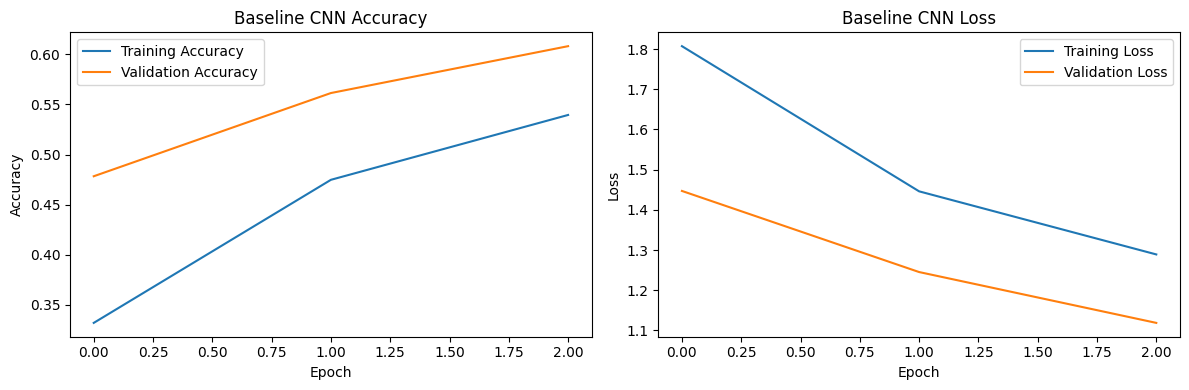

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.6013 - loss: 1.1196
Baseline Test Accuracy: 0.6013


In [28]:
from keras.models import Sequential


from keras.layers import Conv2D,MaxPooling2D,Dense,Flatten

model=Sequential([
  layers.Input(shape=(32,32,3)),
  layers.Rescaling(1.0 / 255),
  layers.Conv2D(32,(3,3),activation='relu',padding='same'),
  layers.MaxPool2D(pool_size=(2,2)),
  layers.Conv2D(64,(3,3),activation='relu',padding='same'),
  layers.MaxPooling2D((2, 2)),

  layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
  layers.MaxPooling2D((2, 2)),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dropout(0.5),
  layers.Dense(10, activation='softmax')

])

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

# model.summary()

history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_data=(X_val, y_val)
)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Baseline CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Baseline CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=1
)

print("Baseline Test Accuracy:", round(test_accuracy, 4))

In [33]:
# PreTrained models

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications import EfficientNetB0

from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobile_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as dense_preprocess

from sklearn.metrics import accuracy_score, precision_score, recall_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf


def evaluate_model(model, test_data, y_true):
    predictions = model.predict(test_data, verbose=0)

    y_pred = np.argmax(predictions, axis=1)
    y_true = y_true.reshape(-1)

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, average='macro', zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, average='macro', zero_division=0
    )

    return accuracy, precision, recall



results = []

# Evaluate the baseline CNN
baseline_accuracy, baseline_precision, baseline_recall = evaluate_model(
    model,
    x_test,
    y_test
)

results.append({
    'Model': 'Baseline CNN',
    'Stage': 'From Scratch',
    'Accuracy': baseline_accuracy,
    'Macro Precision': baseline_precision,
    'Macro Recall': baseline_recall
})

print("Baseline evaluation saved successfully!")

IMAGE_SIZE = 96
BATCH_SIZE = 64

def prepare_dataset(images, labels, preprocess_function):
    dataset = tf.data.Dataset.from_tensor_slices(
        (images, labels.reshape(-1))
    )

    def process_image(image, label):
        image = tf.cast(image, tf.float32)
        image = tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
        image = preprocess_function(image)

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset





Baseline evaluation saved successfully!


In [30]:
def train_pretrained_model(model_name, model_class, preprocess_function,
                           fine_tune=True):

    print("\nTraining:", model_name)

    # Prepare datasets
    train_data = prepare_dataset(
        X_train, y_train, preprocess_function
    )

    val_data = prepare_dataset(
        X_val, y_val, preprocess_function
    )

    test_data = prepare_dataset(
        x_test, y_test, preprocess_function
    )

    # Load the pretrained model
    base_model = model_class(
        weights='imagenet',
        include_top=False,
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    )

    # Freeze pretrained layers
    base_model.trainable = False

    # Build the classification model
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Train the classification head
    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=2,
        verbose=1
    )

    # Evaluate before fine-tuning
    accuracy, precision, recall = evaluate_model(
        model, test_data, y_test
    )

    results.append({
        'Model': model_name,
        'Stage': 'Before Fine-tuning',
        'Accuracy': accuracy,
        'Macro Precision': precision,
        'Macro Recall': recall
    })

    print("Before fine-tuning:", accuracy, precision, recall)

    # Fine-tune selected layers
    if fine_tune:
        base_model.trainable = True

        # Freeze all but the last 20 layers
        for layer in base_model.layers[:-20]:
            layer.trainable = False

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.00001),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )

        model.fit(
            train_data,
            validation_data=val_data,
            epochs=1,
            verbose=1
        )

        # Evaluate after fine-tuning
        accuracy, precision, recall = evaluate_model(
            model, test_data, y_test
        )

        results.append({
            'Model': model_name,
            'Stage': 'After Fine-tuning',
            'Accuracy': accuracy,
            'Macro Precision': precision,
            'Macro Recall': recall
        })

        print("After fine-tuning:", accuracy, precision, recall)

    return model, history

In [ ]:
trained_models = {}

model_configs = {
    'VGG16': (VGG16, vgg_preprocess),
    'ResNet50': (ResNet50, resnet_preprocess),
    'MobileNetV2': (MobileNetV2, mobile_preprocess),
    'DenseNet121': (DenseNet121, dense_preprocess),
    'EfficientNetB0': (EfficientNetB0, lambda x: x)
}


for model_name, (model_class, preprocess_function) in model_configs.items():

    model, history = train_pretrained_model(
        model_name,
        model_class,
        preprocess_function,
        fine_tune=True
    )

    trained_models[model_name] = model

    # Clear unnecessary session objects
    tf.keras.backend.clear_session()


Training: VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/2
 52/625 ━━━━━━━━━━━━━━━━━━━━ 1:01:35 6s/step - accuracy: 0.1412 - loss: 12.6710

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=['Model', 'Stage']
).reset_index(drop=True)

print(results_df.round(4))

results_df.to_csv('model_comparison.csv', index=False)